## 1. Verify the dataset and the provided split

We use train.xlsx and test.xlsx without changing the train/test split.
Each ultrasound image is paired with a mask with the same filename in
the labels folder. We check for duplicate entries, overlap between the
two splits, and missing files.

In [2]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path(
    "/mnt/cv_data/users/seven/datasets/Dataset_BUSI_with_GT_Clean"
)

train_df = pd.read_excel(DATA_ROOT / "train.xlsx")
test_df = pd.read_excel(DATA_ROOT / "test.xlsx")

# Check that image names are present and unique within each split.
for split_name, df in [("Train", train_df), ("Test", test_df)]:
    assert df["Image"].notna().all(), f"{split_name}: missing image names"
    assert df["Image"].is_unique, f"{split_name}: duplicate image names"

# The test images must not appear in the training set.
overlap = set(train_df["Image"]) & set(test_df["Image"])
assert not overlap, f"Train/test overlap: {overlap}"

# Every listed image must have a corresponding mask.
missing = []

for name in pd.concat([train_df["Image"], test_df["Image"]]):
    for folder in ["images", "labels"]:
        path = DATA_ROOT / folder / name
        if not path.is_file():
            missing.append(str(path))

assert not missing, f"Missing files: {missing[:10]}"

print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("Train/test filename overlap:", len(overlap))
print("All listed images and masks exist.")

Training images: 517
Testing images: 130
Train/test filename overlap: 0
All listed images and masks exist.


## 2. Visualize a training image and its segmentation mask

We display an original image, its mask, and an overlay to check spatial
alignment. The mask is read directly to preserve its palette indices
(0 and 1). The highlighted region in the overlay represents label 1.

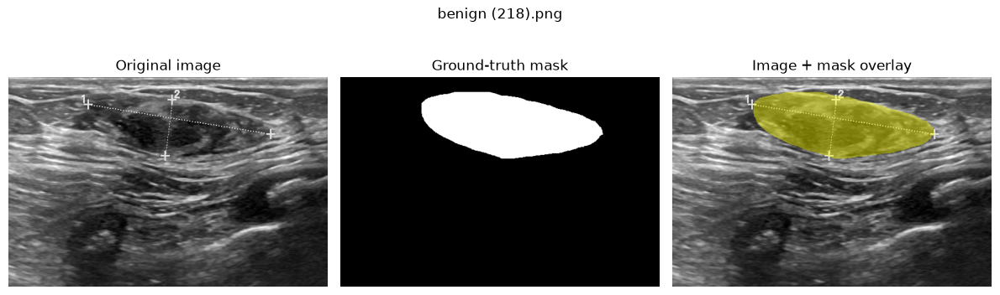

Image shape: (396, 602)
Mask values: [0 1]


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Use a training example for the initial visual inspection.
name = train_df.iloc[0]["Image"]

with Image.open(DATA_ROOT / "images" / name) as img:
    image = np.array(img.convert("L"))

# Preserve the mask's original label values.
with Image.open(DATA_ROOT / "labels" / name) as img:
    mask = np.array(img)

assert mask.ndim == 2, f"Unexpected mask shape: {mask.shape}"
assert image.shape == mask.shape, "Image and mask sizes do not match."
assert set(np.unique(mask)).issubset({0, 1}), "Unexpected mask values."

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image, cmap="gray")
axes[2].imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="autumn",
    alpha=0.45,
    vmin=0,
    vmax=1,
)
axes[2].set_title("Image + mask overlay")

for ax in axes:
    ax.axis("off")

fig.suptitle(name)
plt.tight_layout()
plt.show()

print("Image shape:", image.shape)
print("Mask values:", np.unique(mask))

## 3. Preprocessing and data loading

We retain the training and testing splits provided in the Excel files.
Images are converted to grayscale, resized to 256 × 256, and normalized
to [0, 1]. Masks are resized using nearest-neighbor interpolation to
preserve binary labels.

We use a random seed of 42 and a batch size of 8. No data augmentation
is applied in this initial setup. The training loader shuffles images;
the test loader preserves their order. Test data is not used to select
hyperparameters or training checkpoints.

In [4]:
import random
import torch
from torch.utils.data import Dataset, DataLoader

SEED = 42
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


class BUSISegmentationDataset(Dataset):
    def __init__(self, dataframe, root):
        self.names = dataframe["Image"].tolist()
        self.root = Path(root)

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        name = self.names[index]

        with Image.open(self.root / "images" / name) as img:
            original_size = img.size
            img = img.convert("L")
            img = img.resize(
                IMAGE_SIZE,
                resample=Image.Resampling.BILINEAR,
            )
            image = np.array(img, dtype=np.float32) / 255.0

        with Image.open(self.root / "labels" / name) as label:
            # Validate the original mask before resizing.
            assert label.size == original_size, f"Size mismatch: {name}"
            raw_mask = np.array(label)
            assert raw_mask.ndim == 2, f"Unexpected mask shape: {name}"
            assert set(np.unique(raw_mask)).issubset({0, 1}), (
                f"Unexpected mask values: {name}"
            )

            label = label.resize(
                IMAGE_SIZE,
                resample=Image.Resampling.NEAREST,
            )
            mask = np.array(label, dtype=np.float32)

        # Add the channel dimension: [height, width] -> [1, height, width].
        image = torch.from_numpy(image).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask, name


train_dataset = BUSISegmentationDataset(train_df, DATA_ROOT)
test_dataset = BUSISegmentationDataset(test_df, DATA_ROOT)

# A dedicated generator makes the training shuffle reproducible.
generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# Inspect one batch without performing any training.
images, masks, names = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image range:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks).tolist())
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Image batch shape: torch.Size([8, 1, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image range: 0.0 1.0
Mask values: [0.0, 1.0]
Training batches: 65
Testing batches: 17


## 4. Define the U-Net model

We implement a U-Net variant with four downsampling and upsampling
stages, skip connections, and a base width of 32 channels.

Each convolution block contains two padded 3 × 3 convolutions with
ReLU activation. Max pooling reduces spatial resolution, and transposed
convolutions increase it.

The final 1 × 1 convolution produces one logit per pixel. Sigmoid will
convert logits into tumor probabilities during evaluation. No sigmoid
is applied inside the model because the training loss will use
BCEWithLogitsLoss.

In [6]:
import torch.nn as nn


class DoubleConv(nn.Module):
    """Apply two convolutions while preserving height and width."""

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1
            ),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1
            ),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """U-Net for single-channel binary segmentation."""

    def __init__(self, in_channels=1, out_channels=1, base=32):
        super().__init__()

        self.pool = nn.MaxPool2d(kernel_size=2)

        # Encoder: reduce spatial size and increase channel count.
        self.enc1 = DoubleConv(in_channels, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.enc4 = DoubleConv(base * 4, base * 8)

        self.bottleneck = DoubleConv(base * 8, base * 16)

        # Decoder: upsample and combine with encoder features.
        self.up4 = nn.ConvTranspose2d(
            base * 16, base * 8, kernel_size=2, stride=2
        )
        self.dec4 = DoubleConv(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(
            base * 8, base * 4, kernel_size=2, stride=2
        )
        self.dec3 = DoubleConv(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(
            base * 4, base * 2, kernel_size=2, stride=2
        )
        self.dec2 = DoubleConv(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(
            base * 2, base, kernel_size=2, stride=2
        )
        self.dec1 = DoubleConv(base * 2, base)

        # Produce one raw prediction score (logit) per pixel.
        self.output = nn.Conv2d(base, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


print("U-Net definition is ready.")

U-Net definition is ready.


## 5. Define the training loss

We combine binary cross-entropy with soft Dice loss, using equal weights.

BCEWithLogitsLoss evaluates pixel-level predictions directly from logits.
Soft Dice loss measures overlap between predicted probabilities and the
ground-truth mask. Smaller loss indicates better agreement.

The Dice loss used for optimization is different from the binary Dice
metric used for final evaluation.a

In [7]:
bce_loss = nn.BCEWithLogitsLoss()


def segmentation_loss(logits, targets):
    # Pixel-level binary cross-entropy.
    bce = bce_loss(logits, targets)

    # Convert raw scores into probabilities.
    probabilities = torch.sigmoid(logits)

    # Calculate soft Dice separately for each image.
    dims = (1, 2, 3)
    intersection = (probabilities * targets).sum(dim=dims)
    total = probabilities.sum(dim=dims) + targets.sum(dim=dims)

    smooth = 1e-6
    soft_dice = (2 * intersection + smooth) / (total + smooth)
    dice_loss = 1 - soft_dice.mean()

    return 0.5 * bce + 0.5 * dice_loss


print("Loss function is ready.")

Loss function is ready.


## 6. Train U-Net on the allocated GPU

We train from scratch for 50 epochs using Adam with a learning rate
of 0.001. Only the provided training set is used for optimization.

We reset the random seeds and training-loader generator before training.
We save the latest checkpoint after each epoch and the final model
weights after training. Training loss is recorded in a CSV file.


## 7. Locate the trained model and review training history

The model was trained independently through Slurm using train_unet.py. We load the saved training records and locate the final
weights without repeating training.

If multiple completed runs exist, we select the intended run explicitly.
The test set is not used to choose a training run.

Completed U-Net runs:
/mnt/cv_data/users/seven/Instruction3/outputs/unet/job_383/weights/unet_final.pth

Selected run: job_383
Weights: /mnt/cv_data/users/seven/Instruction3/outputs/unet/job_383/weights/unet_final.pth
Completed epochs: 50
Final training loss: 0.0651681484002439
SciPy available: True


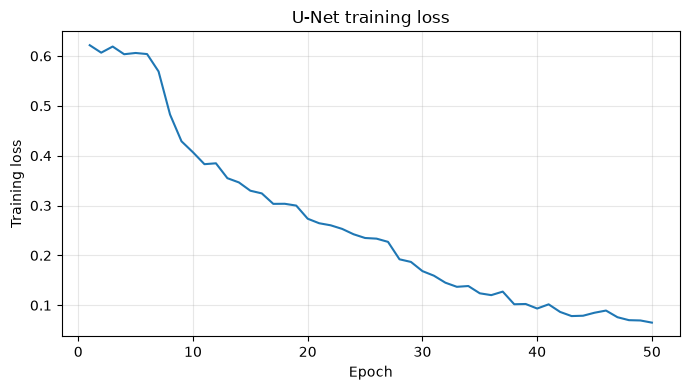

In [8]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import importlib.util

PROJECT_ROOT = Path("/mnt/cv_data/users/seven/Instruction3")

# Find completed runs containing final U-Net weights.
weight_files = sorted(
    (PROJECT_ROOT / "outputs" / "unet").glob(
        "job_*/weights/unet_final.pth"
    )
)

print("Completed U-Net runs:")
for path in weight_files:
    print(path)

if not weight_files:
    raise FileNotFoundError("No unet_final.pth was found.")

# If multiple runs exist, enter the intended folder name below,
# for example: RUN_NAME = "job_12345"
RUN_NAME = None

if RUN_NAME is not None:
    WEIGHTS_PATH = (
        PROJECT_ROOT / "outputs" / "unet"
        / RUN_NAME / "weights" / "unet_final.pth"
    )
    if not WEIGHTS_PATH.is_file():
        raise FileNotFoundError(WEIGHTS_PATH)
elif len(weight_files) == 1:
    WEIGHTS_PATH = weight_files[0]
else:
    raise ValueError(
        "Multiple runs found. Set RUN_NAME to your completed job folder."
    )

RUN_DIR = WEIGHTS_PATH.parent.parent

with open(RUN_DIR / "config.json") as file:
    config = json.load(file)

history = pd.read_csv(RUN_DIR / "training_history.csv")

print("\nSelected run:", RUN_DIR.name)
print("Weights:", WEIGHTS_PATH)
print("Completed epochs:", history["epoch"].iloc[-1])
print("Final training loss:", history["train_loss"].iloc[-1])
print("SciPy available:", importlib.util.find_spec("scipy") is not None)

plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["train_loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("U-Net training loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Predict the test set and save the predicted masks

We load the final trained weights into the same U-Net architecture
defined in Section 4 (1 input channel, 1 output channel, base width 32)
and switch the model to evaluation mode with `model.eval()`.

The test images come from `test_loader`, which uses exactly the same
preprocessing as training: grayscale, 256 × 256, values in [0, 1]. We
run the model without computing gradients (`torch.no_grad()`) and apply
a sigmoid function to convert logits into tumor probabilities.
Probabilities above 0.5 become 1 (tumor); all other pixels become 0
(background). This gives one binary mask for each test image.

Each prediction is saved as a PNG file with the same filename as its
ground-truth mask, in a separate `pred_masks/` folder (the weights are
in `weights/`). Tumor pixels are saved as 255 so the masks are visible
in an image viewer. The evaluation code treats every non-zero pixel as
tumor, so this does not affect the metrics.

In [12]:
import numpy as np
import torch
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# Rebuild the architecture from Section 4 with the same settings as training.
model = UNet(in_channels=1, out_channels=1, base=32).to(device)

# Load the final weights (strict loading raises an error if shapes differ).
state = torch.load(WEIGHTS_PATH, map_location=device)
if isinstance(state, dict) and "model_state_dict" in state:
    state = state["model_state_dict"]      # in case a full checkpoint was saved
model.load_state_dict(state)
model.eval()                               # fixes the behavior of Dropout/BatchNorm

# Predicted masks are stored separately from the weights.
PRED_DIR = RUN_DIR / "pred_masks"
PRED_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.5
test_names = test_df["Image"].tolist()     # order of test.xlsx
saved_names = []

with torch.no_grad():                      # inference only, no gradients
    for images, masks, names in test_loader:
        images = images.to(device)

        logits = model(images)                         # [B, 1, 256, 256]
        probabilities = torch.sigmoid(logits)          # logits -> probabilities
        predictions = (probabilities > THRESHOLD).cpu().numpy()[:, 0]  # [B, 256, 256]

        for pred, name in zip(predictions, names):
            assert pred.shape == IMAGE_SIZE, f"Unexpected shape for {name}"
            # Save as PNG with the same filename as the ground-truth mask.
            Image.fromarray(pred.astype(np.uint8) * 255).save(
                PRED_DIR / name, format="PNG"
            )
            saved_names.append(name)

# Sanity checks: every test image has a prediction, in the expected order.
assert saved_names == test_names, "Saved predictions do not match test.xlsx"
print(f"Saved {len(saved_names)} predicted masks to {PRED_DIR}")

# Quick check that the model is not predicting all-empty masks.
empty = sum(
    not np.array(Image.open(PRED_DIR / n)).any() for n in test_names
)
print(f"Images with an empty predicted mask: {empty} / {len(test_names)}")

Device: cpu
Saved 130 predicted masks to /mnt/cv_data/users/seven/Instruction3/outputs/unet/job_383/pred_masks
Images with an empty predicted mask: 4 / 130


## 9. Evaluate with Dice, IoU and HD95

We compare each predicted mask with its ground-truth mask using three
standard segmentation metrics. Let P be the predicted tumor region and
G the ground-truth tumor region.

- **Dice coefficient** = 2|P ∩ G| / (|P| + |G|). It measures the overlap
  between prediction and ground truth, from 0 (no overlap) to 1
  (perfect). Higher is better.
- **Intersection over Union (IoU)** = |P ∩ G| / |P ∪ G|. It is also an
  overlap measure, but stricter than Dice because the denominator is the
  union. Higher is better.
- **HD95 (95th-percentile Hausdorff distance)** is the 95th percentile of
  the distances (in pixels) between the boundary of P and the boundary
  of G, taken in both directions. It measures boundary error: a small
  value means the predicted outline is close to the true outline. Using
  the 95th percentile instead of the maximum makes it robust to a few
  outlier pixels. Lower is better.

Dice and IoU focus on region overlap, while HD95 focuses on boundary
accuracy, so together they give a more complete picture.

All three models use the same `evaluate.py` and the same conventions,
computed on the 256 × 256 masks. If both masks are empty, Dice = IoU = 1
and HD95 = 0. If only one of them is empty, Dice and IoU are 0 and HD95
is undefined; those images are excluded from the HD95 average and their
number is reported. The per-image results are saved to `metrics.csv`.

In [13]:
import sys

# Make sure the shared evaluation module in the project folder can be imported.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import evaluate

IMG_DIR = DATA_ROOT / "images"
GT_DIR = DATA_ROOT / "labels"

# Per-image Dice, IoU and HD95, with mean ± std printed over the test set.
metrics_df = evaluate.evaluate_folder(
    pred_dir=PRED_DIR,
    gt_dir=GT_DIR,
    names=test_names,
    save_csv=RUN_DIR / "metrics.csv",
)

# Test-set averages (these are the numbers for the comparison table).
summary = metrics_df[["dice", "iou", "hd95"]].agg(["mean", "std"]).round(4)
display(summary)

# Inspect images where the model predicted no tumor at all.
for name in test_names:
    pred_area = int(evaluate.load_mask(PRED_DIR / name).sum())
    gt_area = int(evaluate.load_mask(GT_DIR / name).sum())
    if pred_area == 0:
        print(f"Empty prediction: {name} | ground-truth tumor pixels: {gt_area}")

# Show the 5 test images with the lowest Dice for a first look at failures.
display(metrics_df.sort_values("dice").head(5).round(4))

Dice : 0.6822 ± 0.2989
IoU  : 0.5843 ± 0.3001
HD95 : 43.03 ± 45.98 px (4 images with undefined HD95 skipped)


,dice,iou,hd95
mean,0.6822,0.5843,43.0286
std,0.2989,0.3001,45.9800


Empty prediction: benign (344).png | ground-truth tumor pixels: 3198
Empty prediction: benign (294).png | ground-truth tumor pixels: 4950
Empty prediction: benign (243).png | ground-truth tumor pixels: 6852
Empty prediction: benign (402).png | ground-truth tumor pixels: 3018


,name,dice,iou,hd95
92,benign (243).png,0.0,0.0,NaN
39,benign (294).png,0.0,0.0,NaN
29,benign (196).png,0.0,0.0,155.1444
21,benign (344).png,0.0,0.0,NaN
104,benign (402).png,0.0,0.0,NaN


## 10. Visualize the test results

Numbers alone do not show where a model fails, so we display every test
image in pages of eight. Each row contains four panels:

1. the original ultrasound image;
2. the ground-truth mask;
3. the predicted mask (the per-image Dice score is in the title);
4. an overlay on the original image with color-coded errors:
   - **yellow**: correctly predicted tumor (true positive),
   - **red**: predicted tumor that is not in the ground truth (false
     positive, i.e. over-segmentation),
   - **green**: tumor in the ground truth that the model missed (false
     negative, i.e. under-segmentation).

When reviewing the images, look for missed tumors, over- or
under-segmented regions, and inaccurate boundaries. The figures are also
saved as PNG files so they can be reused in `segmentation_comparison.md`.

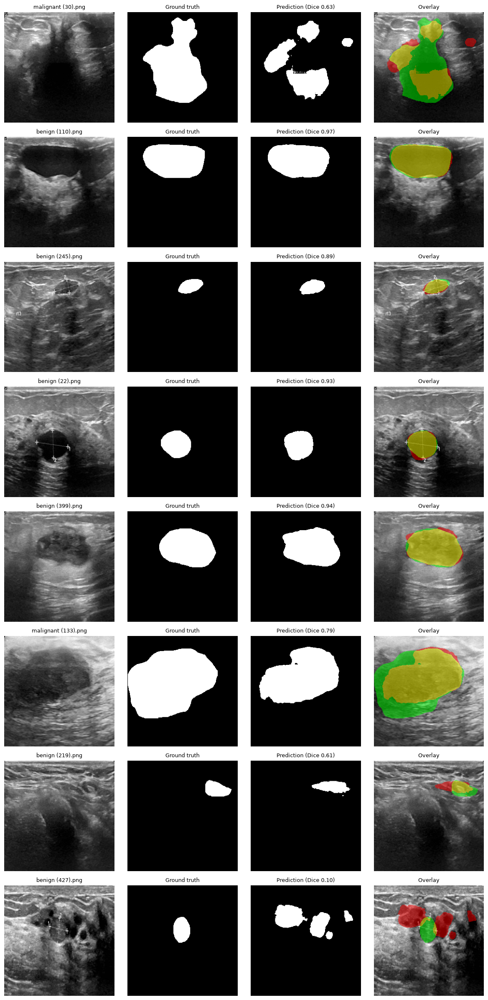

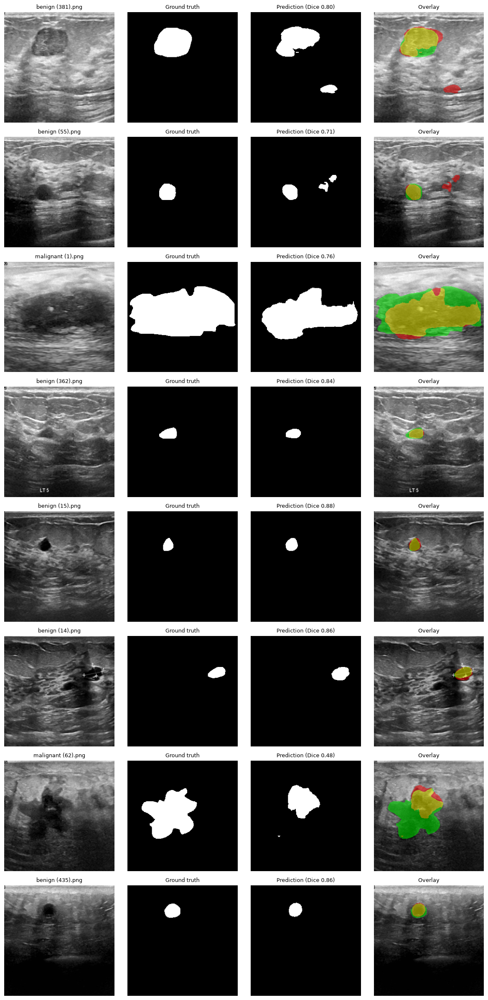

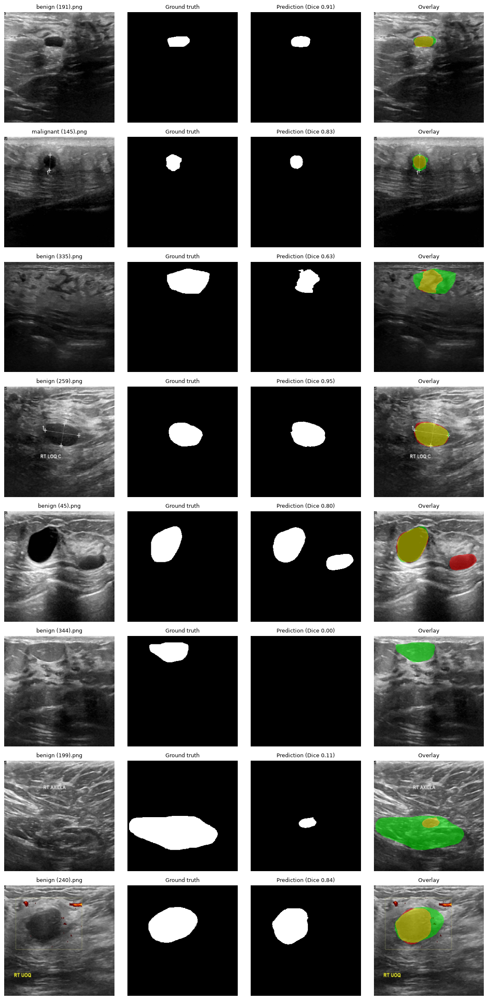

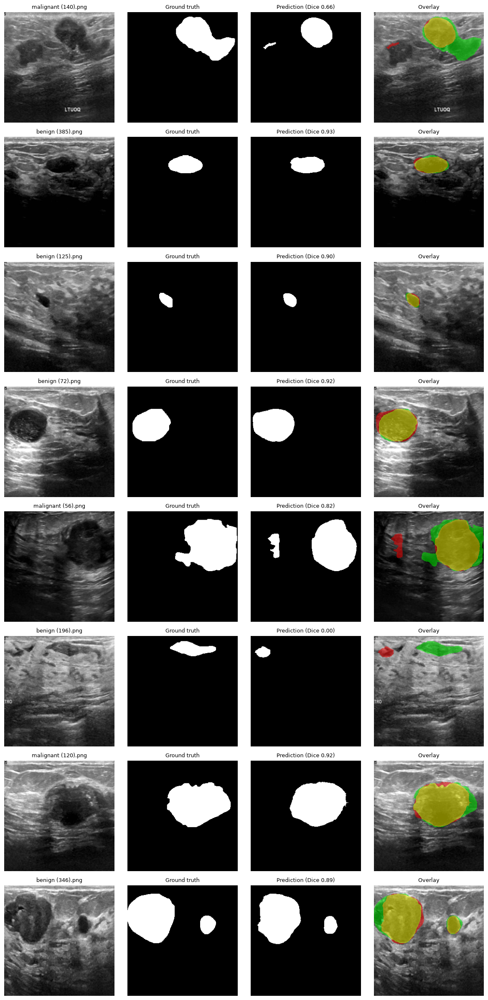

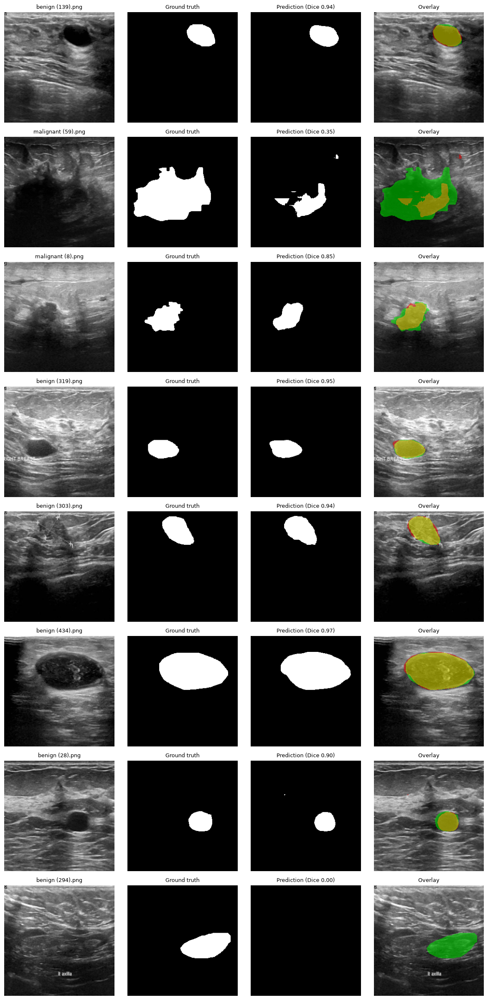

...

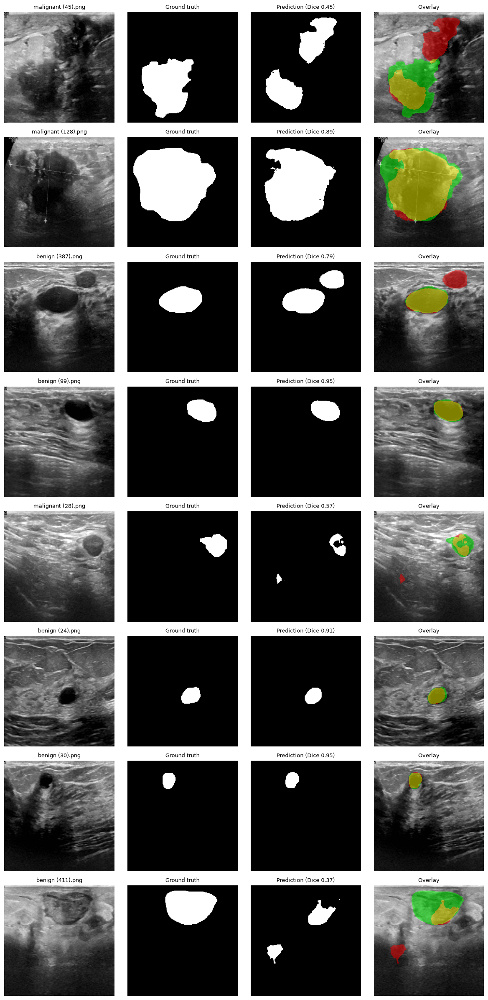

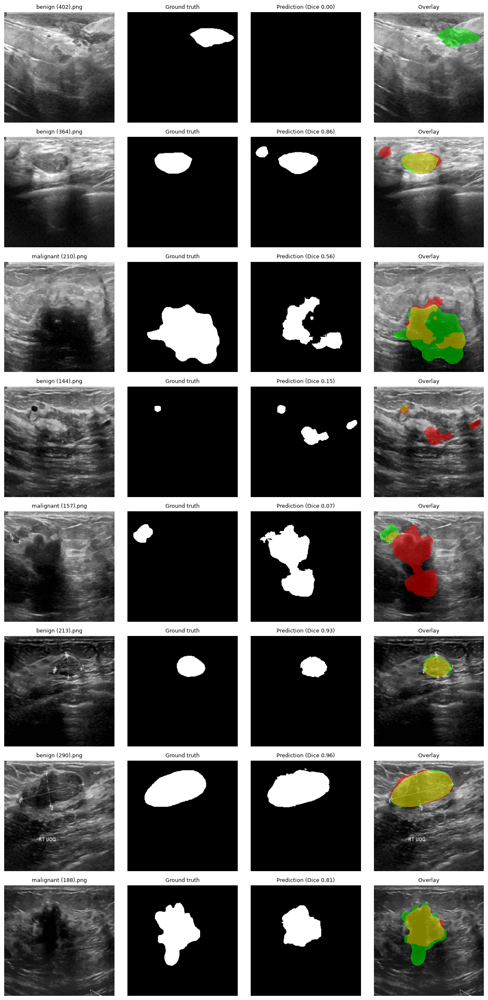

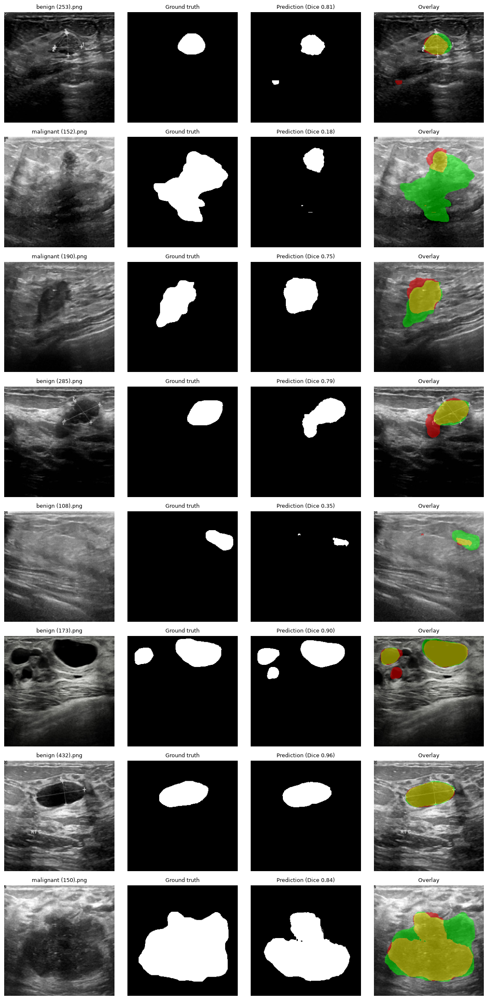

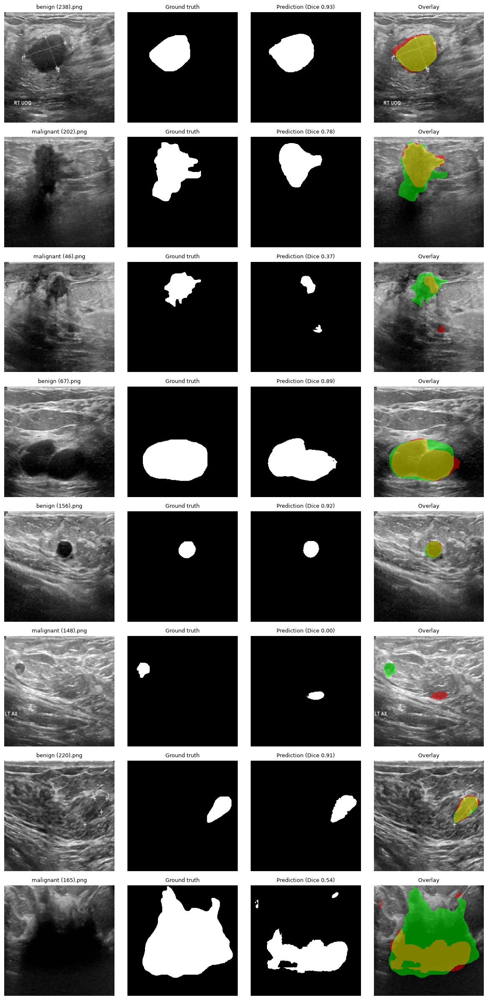

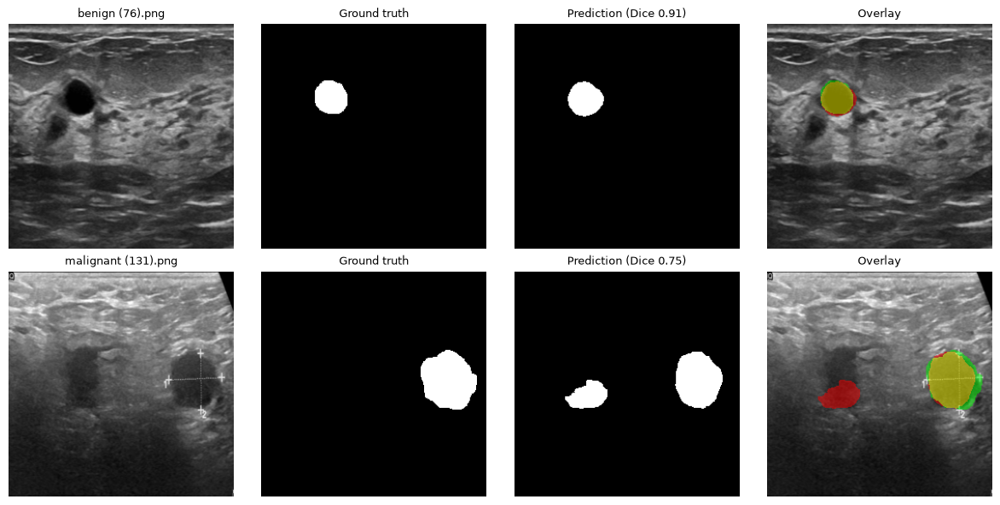

In [15]:
VIS_DIR = RUN_DIR / "visualizations"
VIS_DIR.mkdir(exist_ok=True)

PER_PAGE = 8   # images per figure, keeps every panel readable

# Display all test images: image | ground truth | prediction | error overlay.
for start in range(0, len(test_names), PER_PAGE):
    evaluate.show_results(
        img_dir=IMG_DIR,
        gt_dir=GT_DIR,
        pred_dir=PRED_DIR,
        names=test_names,
        start=start,
        count=PER_PAGE,
        save_path=VIS_DIR / f"vis_{start:03d}.png",
    )

## 11. Supplementary statistics

The mean Dice hides the difference between good and failed cases, and
the HD95 mean above excludes images where HD95 is undefined (the
prediction is empty). To make the comparison between models fair, we
also report the median, the number of failed cases, and an HD95 variant
in which undefined values are replaced by the image diagonal
(256 × √2 ≈ 362 px), the largest possible distance. This variant
penalizes missed tumors instead of ignoring them.

In [16]:
import numpy as np

DIAGONAL = 256 * np.sqrt(2)   # largest possible distance in a 256 x 256 image

n = len(metrics_df)
hd95_penalized = metrics_df["hd95"].fillna(DIAGONAL)

print(f"Median Dice: {metrics_df['dice'].median():.4f}")
print(f"Median IoU : {metrics_df['iou'].median():.4f}")
print(f"Images with Dice = 0   : {(metrics_df['dice'] == 0).sum()} / {n}")
print(f"Images with Dice < 0.5 : {(metrics_df['dice'] < 0.5).sum()} / {n}")
print(f"Images with Dice >= 0.8: {(metrics_df['dice'] >= 0.8).sum()} / {n}")
print(f"HD95 (excluding undefined): {metrics_df['hd95'].mean():.2f} px "
      f"({metrics_df['hd95'].isna().sum()} excluded)")
print(f"HD95 (undefined set to {DIAGONAL:.0f} px): {hd95_penalized.mean():.2f} px")

Median Dice: 0.8114
Median IoU : 0.6826
Images with Dice = 0   : 7 / 130
Images with Dice < 0.5 : 32 / 130
Images with Dice >= 0.8: 69 / 130
HD95 (excluding undefined): 43.03 px (4 excluded)
HD95 (undefined set to 362 px): 52.84 px


## 12. Error analysis

To describe the errors in a structured way, we assign each test image to
a category using the predicted and ground-truth tumor areas:

- **Missed tumor**: the prediction is empty but the ground truth is not.
- **Wrong location**: the prediction is not empty but does not overlap
  the ground truth at all (Dice = 0).
- **Over-segmentation**: the predicted area is more than 1.5 times the
  ground-truth area.
- **Under-segmentation**: the predicted area is less than 0.5 times the
  ground-truth area.
- **Inaccurate boundary**: the areas are similar but Dice is below 0.8.
- **Good**: Dice is at least 0.8.

These thresholds are simple rules chosen for description only; they are
not used for training or model selection. If a ground-truth mask is
empty (no tumor), the image is labeled "No tumor in ground truth".

In [17]:
def categorize(row):
    """Assign one error category from areas and Dice (rules in the text above)."""
    if row["gt_area"] == 0:
        return "No tumor in ground truth"
    if row["pred_area"] == 0:
        return "Missed tumor"
    if row["dice"] == 0:
        return "Wrong location"
    if row["dice"] >= 0.8:
        return "Good"
    ratio = row["pred_area"] / row["gt_area"]
    if ratio > 1.5:
        return "Over-segmentation"
    if ratio < 0.5:
        return "Under-segmentation"
    return "Inaccurate boundary"


# Collect predicted/ground-truth areas and error pixels for every test image.
areas = []
for name in test_names:
    pred = evaluate.load_mask(PRED_DIR / name)
    gt = evaluate.load_mask(GT_DIR / name)
    areas.append({
        "name": name,
        "pred_area": int(pred.sum()),
        "gt_area": int(gt.sum()),
        "false_positive_px": int((pred & ~gt).sum()),   # red in the overlay
        "false_negative_px": int((gt & ~pred).sum()),   # green in the overlay
    })

analysis_df = metrics_df.merge(pd.DataFrame(areas), on="name")
analysis_df["category"] = analysis_df.apply(categorize, axis=1)
analysis_df.to_csv(RUN_DIR / "error_analysis.csv", index=False)

# Number of images per category and their mean Dice.
display(
    analysis_df.groupby("category")["dice"]
    .agg(count="count", mean_dice="mean")
    .round(4)
    .sort_values("count", ascending=False)
)

# Image names in each failure category, to find them quickly in the figures.
for category in ["Missed tumor", "Wrong location", "Over-segmentation",
                 "Under-segmentation", "Inaccurate boundary"]:
    names_in_category = analysis_df.loc[analysis_df["category"] == category, "name"]
    print(f"\n{category} ({len(names_in_category)}):")
    print(", ".join(names_in_category) if len(names_in_category) else "none")

# Does the model do worse on small tumors? Mean Dice by ground-truth size.
analysis_df["size_group"] = pd.qcut(
    analysis_df["gt_area"], 3, labels=["small", "medium", "large"]
)
display(
    analysis_df.groupby("size_group", observed=True)["dice"]
    .agg(["count", "mean"]).round(4)
)

,count,mean_dice
category,,
Good,69,0.8999
Inaccurate boundary,23,0.6996
Under-segmentation,22,0.3536
Over-segmentation,9,0.3034
Missed tumor,4,0.0000
Wrong location,3,0.0000



Missed tumor (4):
benign (344).png, benign (294).png, benign (243).png, benign (402).png

Wrong location (3):
benign (196).png, benign (235).png, malignant (148).png

Over-segmentation (9):
benign (427).png, malignant (181).png, benign (153).png, benign (369).png, benign (169).png, malignant (64).png, benign (428).png, benign (144).png, malignant (157).png

Under-segmentation (22):
malignant (62).png, benign (335).png, benign (199).png, malignant (59).png, benign (122).png, benign (171).png, malignant (89).png, benign (395).png, malignant (138).png, benign (398).png, benign (409).png, malignant (36).png, benign (336).png, benign (417).png, benign (141).png, benign (64).png, benign (411).png, malignant (210).png, malignant (152).png, benign (108).png, malignant (46).png, malignant (165).png

Inaccurate boundary (23):
malignant (30).png, malignant (133).png, benign (219).png, benign (55).png, malignant (1).png, malignant (140).png, malignant (44).png, malignant (203).png, malignant (52)

,count,mean
size_group,,
small,44,0.6957
medium,43,0.7225
large,43,0.6282


## 13. Why were the tumors missed?

An empty mask means that no pixel exceeded the 0.5 threshold. To see
whether the model detected the missed tumors weakly or not at all, we
print the tumor probability inside the ground-truth region for every
"Missed tumor" image: the highest and the mean value inside the tumor,
and the highest value outside it. This is used only for explanation; the
threshold is not changed and the test set is not used to tune anything.

In [18]:
# Names of the missed-tumor images found in the error analysis above.
missed = analysis_df.loc[analysis_df["category"] == "Missed tumor", "name"].tolist()
dataset_index = {n: i for i, n in enumerate(test_names)}

model.eval()
with torch.no_grad():
    for name in missed:
        image, mask, _ = test_dataset[dataset_index[name]]
        prob = torch.sigmoid(model(image.unsqueeze(0).to(device)))[0, 0].cpu().numpy()
        gt = mask[0].numpy() > 0                      # ground-truth tumor pixels
        print(f"{name}: max probability in tumor = {prob[gt].max():.3f}, "
              f"mean in tumor = {prob[gt].mean():.3f}, "
              f"max outside tumor = {prob[~gt].max():.3f}")

benign (344).png: max probability in tumor = 0.000, mean in tumor = 0.000, max outside tumor = 0.016
benign (294).png: max probability in tumor = 0.004, mean in tumor = 0.000, max outside tumor = 0.393
benign (243).png: max probability in tumor = 0.000, mean in tumor = 0.000, max outside tumor = 0.016
benign (402).png: max probability in tumor = 0.159, mean in tumor = 0.002, max outside tumor = 0.013


## 14. Summary of the U-Net results

**Overall performance.** On the 130 test images, U-Net reaches a mean
Dice of 0.6822 ± 0.2989, a mean IoU of 0.5843 ± 0.3001 and a mean HD95
of 43.03 ± 45.98 px. Four images with an empty prediction have no
defined HD95 and are excluded from this mean; when they are counted as
362 px (the image diagonal), the mean HD95 is 52.84 px. The median Dice
(0.8114) is clearly higher than the mean, and the standard deviation is
large, so performance varies strongly between images: 69 of 130 images
(53%) reach Dice ≥ 0.8, 32 images (25%) have Dice < 0.5, and 7 images
(5%) have Dice = 0. A minority of failed cases therefore lowers the
average considerably.

**Distribution of error types.** Using the rules in Section 12, 69 images
are segmented well (mean Dice 0.8999), 23 have an inaccurate boundary
(0.6996), 22 are under-segmented (0.3536), 9 are over-segmented (0.3034),
4 are missed tumors and 3 have a wrong location (both 0.0000). Under-
segmentation (22) and missed tumors (4) together are much more frequent
than over-segmentation (9), so the model errs more often by predicting
too little tumor than too much.

**Missed tumors.** The model predicted no tumor for 4 benign images
(benign (243), (294), (344) and (402)), whose ground-truth tumors cover
3,018 to 6,852 pixels. These images receive Dice = IoU = 0 and have no
defined HD95. In the overlays, the whole tumor region is a false
negative. Visually, the tumors in these images have low contrast with the
surrounding tissue and no clear boundary, and the surrounding tissue is
heterogeneous or striped. Two of the four images carry an "axilla"
annotation (benign (243) and (294)), which may indicate a different
anatomical region from typical breast lesions, but this is only an
observation from these examples. Other benign images, such as
benign (265) (Dice 0.88) and benign (364) (Dice 0.86), are segmented
well, so the failures are specific to low-contrast cases. The maximum
tumor probability inside the missed tumors was between 0.000 and 0.159
(mean inside the tumor ≤ 0.002), far below the 0.5 threshold. The model
therefore did not detect these tumors at all, rather than missing the
threshold narrowly, so a different threshold would not have helped.

**Wrong location.** Three images have a non-empty prediction that does
not overlap the ground truth at all (Dice = 0): benign (196), benign (235)
and malignant (148). In benign (196), the ground truth is an elongated
horizontal tumor in the upper-middle part of the image, whereas the model
predicted a small region at the upper-left image border, far from the
tumor (HD95 = 155 px). In malignant (148), the ground truth is a small,
round, dark lesion in the upper-left part of the image, while the model
predicted a different elongated region in the center-right part. In both
images the overlay shows false-positive (red) and false-negative (green)
regions at the same time, so these are localization errors rather than
missed detections: the model responded to the wrong structure and did not
respond to the tumor. [FILL: describe benign (235) after looking at the
figure.] The image of malignant (148) is annotated "LT AX" (left axilla),
like two of the four missed tumors above, which may indicate a different
anatomical region from typical breast lesions; this should be verified
on the other axilla images before drawing a conclusion.

**Over- and under-segmentation.** Under-segmentation affects 22 images
and over-segmentation 9. Their mean Dice is low (0.35 and 0.30), which
means that in these images the predicted region differs strongly from
the true tumor in size, not only at the edges.

**Boundary quality.** In 23 images (18%), the predicted area is similar
to the true area (between 0.5 and 1.5 times) but Dice is still below
0.8 (mean 0.70). In these cases the model finds the tumor and roughly its
size, but the predicted outline deviates from the ground-truth outline.

**Tumor size.** The images were split into three equally sized groups by
ground-truth tumor area. The mean Dice is 0.6957 for small tumors
(44 images), 0.7225 for medium tumors (43 images) and 0.6282 for large
tumors (43 images). Contrary to the expectation that small tumors are the
hardest, the large-tumor group has the lowest mean Dice. This is a
descriptive result on a small test set, and the group means are strongly
affected by the few images with Dice = 0, so we do not draw a causal
conclusion from it.

**Possible causes and limitations.** The final training loss (0.065)
contrasts with the test Dice of 0.68, which may indicate overfitting;
because no validation set or data augmentation was used, and the Dice on
the training set was not measured, we cannot confirm this. The final
weights after a fixed number of epochs are used, and the test set was
not used to select a checkpoint or any hyperparameter. All models are
evaluated with the same split and settings, so these results serve as
the baseline for the comparison with DeepLabV3+ and nnU-Net.